In [1]:
import pandas as pd
from nixtla import NixtlaClient
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
import os
from datetime import timedelta

# Setup
nixtla_client = NixtlaClient(api_key="nixak-541cafc001c04aac20da974612ecdc3776ca1fba84395e3e4337876027640e21b7699922f7ad3cf9")  # ← THAY KEY CỦA BẠN

os.makedirs("timegpt_backtest", exist_ok=True)
os.makedirs("timegpt_forecast_30days", exist_ok=True)

print("Setup hoan tat.")

Setup hoan tat.


In [2]:
df = pd.read_csv('merged_data_final.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values(['id', 'timestamp'])

required_cols = {'id', 'timestamp', 'Close'}
missing_cols = required_cols - set(df.columns)
if missing_cols:
    print(f"Thieu cot bat buoc: {missing_cols}")
    print(f"Cac cot hien co: {list(df.columns)}")
    raise ValueError("Du lieu khong dung dinh dang.")

print(f"Tong so ma: {df['id'].nunique()}")
print(f"Ngay moi nhat: {df['timestamp'].max().date()}\n")

backtest_results = {}
forecast_results = {}
error_log = []
skipped_log = []
stocks = df['id'].unique()

for stock in stocks:
    stock_df = df[df['id'] == stock][['timestamp', 'Close']].copy()
    stock_df = stock_df.dropna().sort_values('timestamp')
    stock_df = stock_df.drop_duplicates(subset=['timestamp'], keep='last')
    
    # Lam sach du lieu ngay: bo trung lap, bo thieu ngay bang B-day va ffill
    if stock_df.empty:
        skipped_log.append((stock, 0))
        print(f"⚠️ {stock}: Khong co du lieu sau khi lam sach -> bo qua")
        continue
    
    date_index = pd.date_range(stock_df['timestamp'].min(), stock_df['timestamp'].max(), freq='B')
    stock_df = stock_df.set_index('timestamp').reindex(date_index)
    stock_df['Close'] = stock_df['Close'].ffill()
    stock_df = stock_df.dropna().reset_index().rename(columns={'index': 'timestamp'})
    stock_df['id'] = stock
    
    if len(stock_df) < 90:
        skipped_log.append((stock, len(stock_df)))
        print(f"⚠️ {stock}: Chi co {len(stock_df)} ngay -> bo qua")
        continue
    
    test_df = stock_df.tail(30).copy()
    test_dates = test_df['timestamp'].tolist()
    rolling_preds = []
    rolling_actuals = []
    rolling_prev_actuals = []
    
    print(f"Dang rolling backtest {stock} | 30 ngay cuoi, horizon=1")
    
    try:
        for dt in test_dates:
            train_df = stock_df[stock_df['timestamp'] < dt].copy()
            if len(train_df) < 60:
                continue
            
            train_input = train_df[['timestamp', 'Close']].rename(columns={'timestamp': 'ds', 'Close': 'y'})
            train_input['unique_id'] = stock
            
            fc = nixtla_client.forecast(
            df=train_input,
            h=1,
            time_col='ds',
            target_col='y',
            freq='B',
            level=[80, 90]
            )
            pred = float(fc['TimeGPT'].iloc[0])
            actual = float(stock_df.loc[stock_df['timestamp'] == dt, 'Close'].iloc[0])
            prev_actual = float(train_df['Close'].iloc[-1])
            
            rolling_preds.append(pred)
            rolling_actuals.append(actual)
            rolling_prev_actuals.append(prev_actual)
        
        if len(rolling_actuals) < 10:
            skipped_log.append((stock, len(rolling_actuals)))
            print(f"⚠️ {stock}: Qua it ngay valid ({len(rolling_actuals)}) -> bo qua")
            continue
        
        rolling_actuals_arr = np.array(rolling_actuals)
        rolling_preds_arr = np.array(rolling_preds)
        rolling_prev_arr = np.array(rolling_prev_actuals)
        
        mae = mean_absolute_error(rolling_actuals_arr, rolling_preds_arr)
        rmse = np.sqrt(mean_squared_error(rolling_actuals_arr, rolling_preds_arr))
        mape = np.mean(np.abs((rolling_actuals_arr - rolling_preds_arr) / rolling_actuals_arr)) * 100
        # Huong di: so sanh bien dong thuc te va du doan so voi ngay truoc do
        dir_acc = np.mean(np.sign(rolling_actuals_arr - rolling_prev_arr) == np.sign(rolling_preds_arr - rolling_prev_arr)) * 100
        
        backtest_results[stock] = {
            'MAE': round(mae, 4),
            'RMSE': round(rmse, 4),
            'MAPE (%)': round(mape, 2),
            'Directional Accuracy (%)': round(dir_acc, 2),
            'Rolling Days': len(rolling_actuals)
        }
        
        rolling_detail = pd.DataFrame({
            'ds': test_dates[:len(rolling_actuals)],
            'Actual': rolling_actuals,
            'Pred': rolling_preds,
            'Prev Actual': rolling_prev_actuals
        })
        rolling_detail['Error'] = rolling_detail['Actual'] - rolling_detail['Pred']
        rolling_detail['Error %'] = (rolling_detail['Error'] / rolling_detail['Actual']) * 100
        rolling_detail.to_csv(f"timegpt_backtest/rolling_1day_{stock}.csv", index=False)
        
        full_input = stock_df[['timestamp', 'Close']].rename(columns={'timestamp': 'ds', 'Close': 'y'})
        full_input['unique_id'] = stock
        forward_fc = nixtla_client.forecast(
            df=full_input,
            h=30,
            time_col='ds',
            target_col='y',
            freq='B',
            level=[80, 90]
        )
        forward_fc.to_csv(f"timegpt_forecast_30days/forecast_{stock}.csv", index=False)
        forecast_results[stock] = forward_fc
        
        print(f"   ✅ {stock} OK | MAPE = {mape:.2f}% | Dir.Acc = {dir_acc:.1f}%")
        
    except Exception as e:
        error_log.append((stock, type(e).__name__, str(e)))
        print(f"LOI {stock}: {type(e).__name__} - {e}")

print("\n" + "="*70)
print(f"So ma thanh cong: {len(backtest_results)}")
print(f"So ma bi skip (<90 ngay or it ngay valid): {len(skipped_log)}")
print(f"So ma bi loi: {len(error_log)}")

if error_log:
    error_df = pd.DataFrame(error_log, columns=['id', 'error_type', 'error_message'])
    print("\nCac loi thuong gap:")
    display(error_df.head(20))

if backtest_results:
    backtest_df = pd.DataFrame.from_dict(backtest_results, orient='index')
    backtest_df = backtest_df.sort_values('MAPE (%)')
    backtest_df.to_csv("timegpt_backtest/backtest_summary.csv")
    
    print("KET QUA BACKTEST TIME GPT (Rolling 1-day, 30 ngay cuoi)")
    display(backtest_df)
    print(f"\nMAPE trung binh: {backtest_df['MAPE (%)'].mean():.2f}%")
else:
    print("KHONG CO MA NAO FORECAST THANH CONG!")
    print("   -> Xem bang loi o tren de biet ly do.")

Tong so ma: 6
Ngay moi nhat: 2025-12-31



INFO:nixtla.nixtla_client:Validating inputs...
INFO:nixtla.nixtla_client:Preprocessing dataframes...
INFO:nixtla.nixtla_client:Querying model metadata...


Dang rolling backtest FPT | 30 ngay cuoi, horizon=1


INFO:nixtla.nixtla_client:Restricting input...
INFO:nixtla.nixtla_client:Calling Forecast Endpoint...
INFO:nixtla.nixtla_client:Validating inputs...
INFO:nixtla.nixtla_client:Preprocessing dataframes...
INFO:nixtla.nixtla_client:Restricting input...
INFO:nixtla.nixtla_client:Calling Forecast Endpoint...
INFO:nixtla.nixtla_client:Validating inputs...
INFO:nixtla.nixtla_client:Preprocessing dataframes...
INFO:nixtla.nixtla_client:Restricting input...
INFO:nixtla.nixtla_client:Calling Forecast Endpoint...
INFO:nixtla.nixtla_client:Validating inputs...
INFO:nixtla.nixtla_client:Preprocessing dataframes...
INFO:nixtla.nixtla_client:Restricting input...
INFO:nixtla.nixtla_client:Calling Forecast Endpoint...
INFO:nixtla.nixtla_client:Validating inputs...
INFO:nixtla.nixtla_client:Preprocessing dataframes...
INFO:nixtla.nixtla_client:Restricting input...
INFO:nixtla.nixtla_client:Calling Forecast Endpoint...
INFO:nixtla.nixtla_client:Validating inputs...
INFO:nixtla.nixtla_client:Preprocessing

   ✅ FPT OK | MAPE = 1.07% | Dir.Acc = 50.0%
Dang rolling backtest HPG | 30 ngay cuoi, horizon=1


...

   ✅ VHM OK | MAPE = 3.13% | Dir.Acc = 43.3%
Dang rolling backtest VNM | 30 ngay cuoi, horizon=1


INFO:nixtla.nixtla_client:Validating inputs...
INFO:nixtla.nixtla_client:Preprocessing dataframes...
INFO:nixtla.nixtla_client:Restricting input...
INFO:nixtla.nixtla_client:Calling Forecast Endpoint...
INFO:nixtla.nixtla_client:Validating inputs...
INFO:nixtla.nixtla_client:Preprocessing dataframes...
INFO:nixtla.nixtla_client:Restricting input...
INFO:nixtla.nixtla_client:Calling Forecast Endpoint...
INFO:nixtla.nixtla_client:Validating inputs...
INFO:nixtla.nixtla_client:Preprocessing dataframes...
INFO:nixtla.nixtla_client:Restricting input...
INFO:nixtla.nixtla_client:Calling Forecast Endpoint...
INFO:nixtla.nixtla_client:Validating inputs...
INFO:nixtla.nixtla_client:Preprocessing dataframes...
INFO:nixtla.nixtla_client:Restricting input...
INFO:nixtla.nixtla_client:Calling Forecast Endpoint...
INFO:nixtla.nixtla_client:Validating inputs...
INFO:nixtla.nixtla_client:Preprocessing dataframes...
INFO:nixtla.nixtla_client:Restricting input...
INFO:nixtla.nixtla_client:Calling Foreca

   ✅ VNM OK | MAPE = 1.67% | Dir.Acc = 33.3%

So ma thanh cong: 6
So ma bi skip (<90 ngay or it ngay valid): 0
So ma bi loi: 0
KET QUA BACKTEST TIME GPT (Rolling 1-day, 30 ngay cuoi)


,MAE,RMSE,MAPE (%),Directional Accuracy (%),Rolling Days
VCB,0.4511,0.6207,0.78,36.67,30
HPG,0.2415,0.2941,0.91,53.33,30
FPT,1.0236,1.2430,1.07,50.00,30
VNM,1.0425,1.2866,1.67,33.33,30
SSI,0.5970,0.7659,2.00,50.00,30
VHM,3.3818,4.7126,3.13,43.33,30



MAPE trung binh: 1.59%


Backtest chi tiet 30 ngay gan nhat - FPT


,ds,Actual,TimeGPT,Error,Error %
0,2025-11-20,97.980,NaN,NaN,NaN
1,2025-11-21,99.762,NaN,NaN,NaN
2,2025-11-24,99.168,NaN,NaN,NaN
3,2025-11-25,98.673,NaN,NaN,NaN
4,2025-11-26,97.980,NaN,NaN,NaN
5,2025-11-27,98.475,NaN,NaN,NaN
6,2025-11-28,96.100,NaN,NaN,NaN
7,2025-12-01,96.600,NaN,NaN,NaN
8,2025-12-02,96.600,NaN,NaN,NaN
9,2025-12-03,96.600,NaN,NaN,NaN


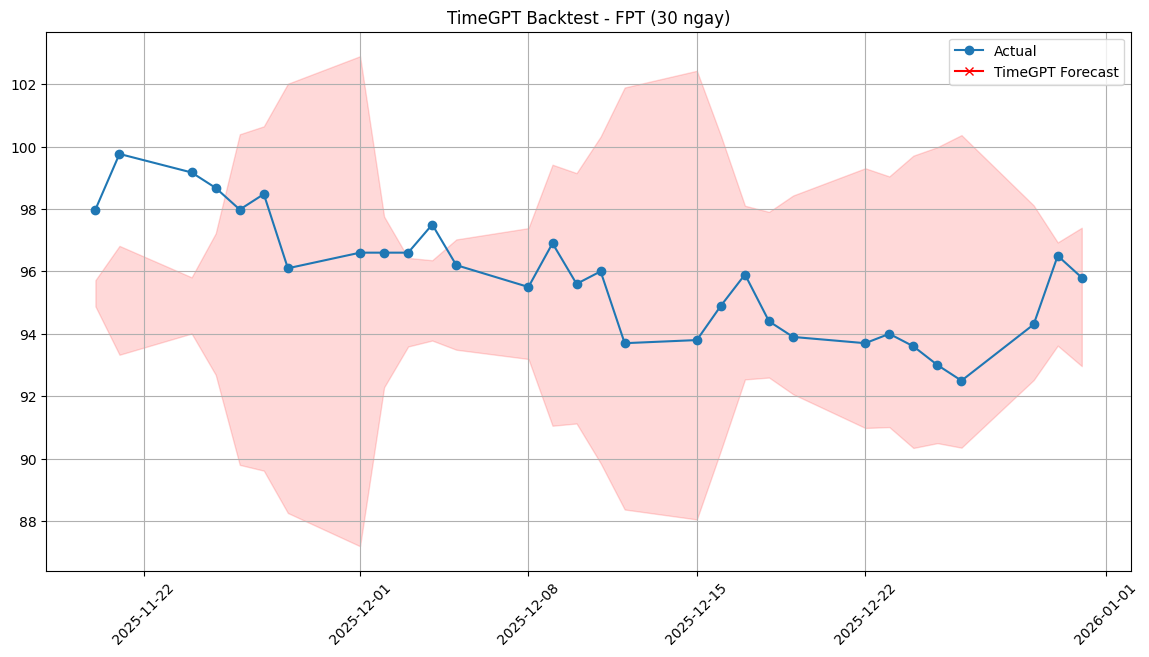

In [3]:
stock_example = "FPT"   # thay bang ma ban muon xem

if stock_example in forecast_results:
    fc = forecast_results[stock_example]
    # Lay actual 30 ngay cuoi
    actual = df[df['id'] == stock_example].tail(30)[['timestamp', 'Close']].copy()
    actual = actual.rename(columns={'timestamp': 'ds', 'Close': 'Actual'})
    
    compare = pd.merge(actual, fc[['ds', 'TimeGPT']], on='ds', how='left')
    compare['Error'] = compare['Actual'] - compare['TimeGPT']
    compare['Error %'] = (compare['Error'] / compare['Actual']) * 100
    
    print(f"Backtest chi tiet 30 ngay gan nhat - {stock_example}")
    display(compare.round(4))
    
    # Plot
    import matplotlib.pyplot as plt
    plt.figure(figsize=(14, 7))
    plt.plot(compare['ds'], compare['Actual'], label='Actual', marker='o')
    plt.plot(compare['ds'], compare['TimeGPT'], label='TimeGPT Forecast', marker='x', color='red')
    plt.fill_between(compare['ds'], 
                     fc['TimeGPT-lo-90'], fc['TimeGPT-hi-90'], color='red', alpha=0.15)
    plt.title(f'TimeGPT Backtest - {stock_example} (30 ngay)')
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.show()

In [4]:
print("Tom tat backtest TimeGPT Zero-shot (30 ngay hold-out):")
if 'backtest_df' in globals():
    display(backtest_df)
    print(f"MAPE trung binh: {backtest_df['MAPE (%)'].mean():.2f}%")
    print(f"Directional Accuracy trung binh: {backtest_df['Directional Accuracy (%)'].mean():.2f}%")
elif backtest_results:
    backtest_df = pd.DataFrame.from_dict(backtest_results, orient='index').sort_values('MAPE (%)')
    display(backtest_df)
    print(f"MAPE trung binh: {backtest_df['MAPE (%)'].mean():.2f}%")
    print(f"Directional Accuracy trung binh: {backtest_df['Directional Accuracy (%)'].mean():.2f}%")
else:
    print("Chua co ket qua backtest. Hay chay lai cell 2 truoc.")

Tom tat backtest TimeGPT Zero-shot (30 ngay hold-out):


,MAE,RMSE,MAPE (%),Directional Accuracy (%),Rolling Days
VCB,0.4511,0.6207,0.78,36.67,30
HPG,0.2415,0.2941,0.91,53.33,30
FPT,1.0236,1.2430,1.07,50.00,30
VNM,1.0425,1.2866,1.67,33.33,30
SSI,0.5970,0.7659,2.00,50.00,30
VHM,3.3818,4.7126,3.13,43.33,30


MAPE trung binh: 1.59%
Directional Accuracy trung binh: 44.44%
